In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Titanic dataset
df = pd.read_csv("Titanic.csv")

# Display first 5 rows
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [4]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
print(df.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [6]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
# Make a copy
titanic = df.copy()

# Fill missing Age with median
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())

# Fill missing Embarked with mode
titanic["Embarked"] = titanic["Embarked"].fillna(
    titanic["Embarked"].mode()[0]
)

# Drop Cabin because most values are missing
titanic = titanic.drop(columns=["Cabin"])

# Check again
print(titanic.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


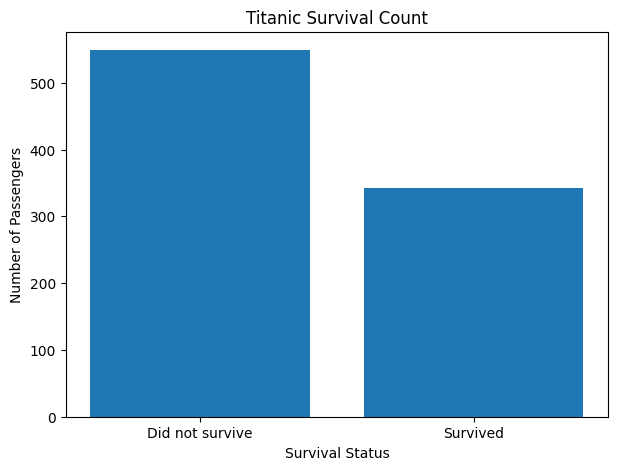

In [8]:
survival_counts = titanic["Survived"].value_counts().sort_index()

plt.figure(figsize=(7,5))

plt.bar(
    ["Did not survive", "Survived"],
    survival_counts.values
)

plt.title("Titanic Survival Count")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")

plt.show()

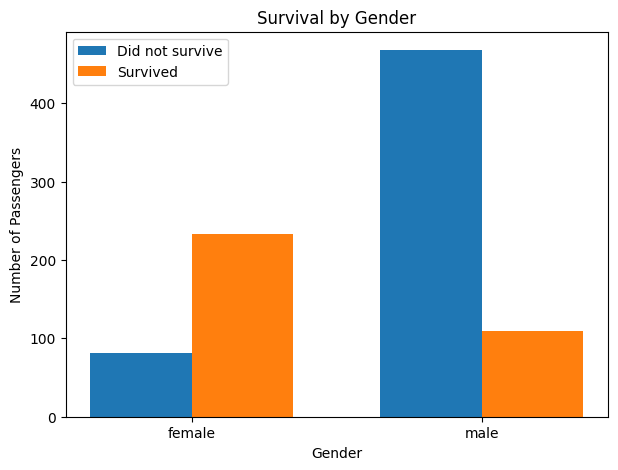

In [9]:
gender_survival = pd.crosstab(
    titanic["Sex"],
    titanic["Survived"]
)

plt.figure(figsize=(7,5))

x = range(len(gender_survival.index))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    gender_survival[0],
    width,
    label="Did not survive"
)

plt.bar(
    [i + width/2 for i in x],
    gender_survival[1],
    width,
    label="Survived"
)

plt.xticks(list(x), gender_survival.index)

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend()

plt.show()

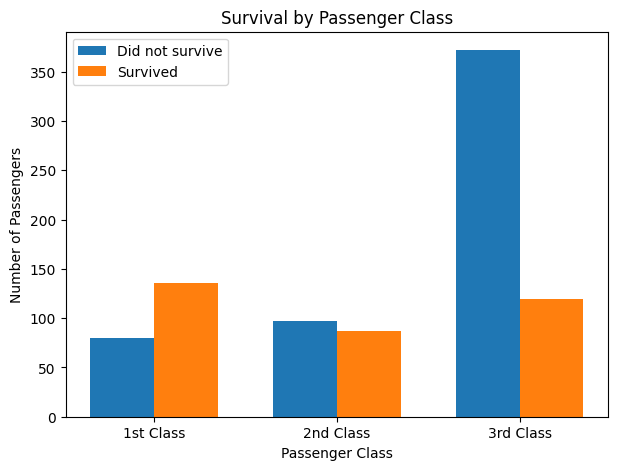

In [10]:
class_survival = pd.crosstab(
    titanic["Pclass"],
    titanic["Survived"]
)

plt.figure(figsize=(7,5))

x = range(len(class_survival.index))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    class_survival[0],
    width,
    label="Did not survive"
)

plt.bar(
    [i + width/2 for i in x],
    class_survival[1],
    width,
    label="Survived"
)

plt.xticks(
    list(x),
    ["1st Class", "2nd Class", "3rd Class"]
)

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend()

plt.show()

Interpretation

There is a very large difference between male and female survival.

Most females survived.
Most males did not survive.
Female survival rate was approximately 74.2%.
Male survival rate was approximately 18.9%.

This indicates that gender was strongly associated with survival.

Interpretation

Passenger class had a significant relationship with survival.

Survival rates were:

1st Class: 62.96%
2nd Class: 47.28%
3rd Class: 24.24%

Therefore, passengers in 1st class had the highest survival rate, while passengers in 3rd class had the lowest.

Interpretation

The histogram shows that most Titanic passengers were relatively young adults.

The median age was 28 years.

There were passengers ranging from very young children to elderly passengers, but the largest concentration was around the young-adult age range.

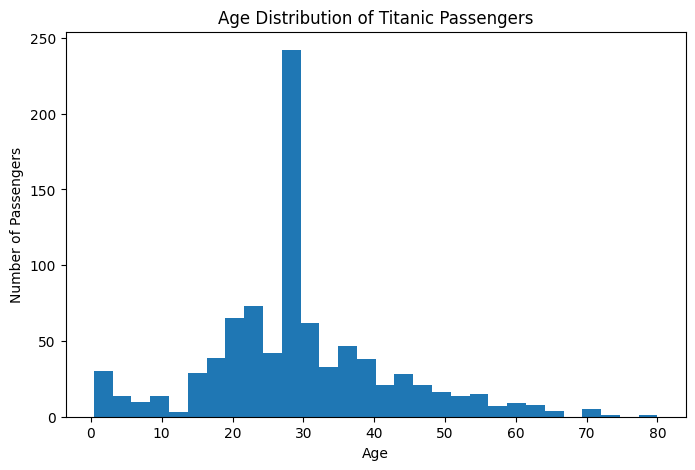

In [11]:
plt.figure(figsize=(8,5))

plt.hist(titanic["Age"], bins=30)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

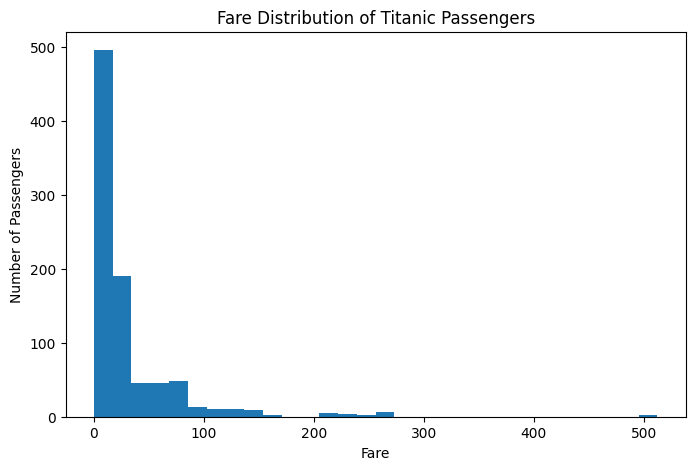

In [12]:
plt.figure(figsize=(8,5))

plt.hist(titanic["Fare"], bins=30)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()

Interpretation

The fare distribution is right-skewed.

Most passengers paid relatively low fares, while a small number of passengers paid very high fares.

The median fare was approximately 14.45, while the maximum fare was 512.33.

This large difference indicates the presence of some high-fare passengers.

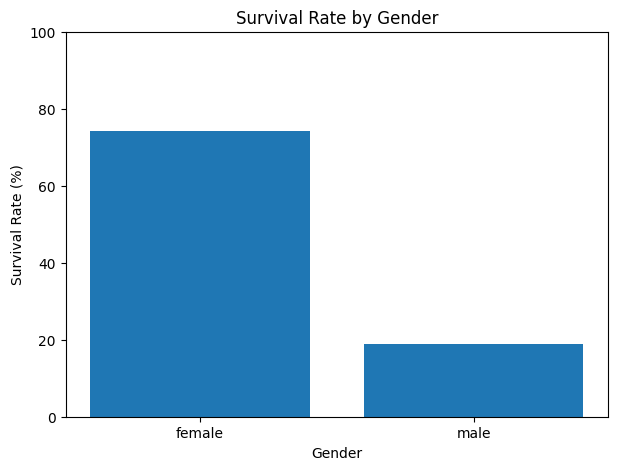

In [13]:
survival_rate_gender = (
    titanic.groupby("Sex")["Survived"].mean() * 100
)

plt.figure(figsize=(7,5))

plt.bar(
    survival_rate_gender.index,
    survival_rate_gender.values
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")

plt.ylim(0, 100)

plt.show()

Interpretation

The chart clearly shows that females had a much higher survival rate than males.

Gender	Survival Rate
Female	74.2%
Male	18.9%

This is one of the strongest patterns in the Titanic dataset.

## Final Insights

The Titanic dataset contains information about 891 passengers and 12 different variables. The overall survival rate was approximately 38.4%, which means that most passengers in the dataset did not survive.

The analysis shows that gender was one of the strongest factors associated with survival. Approximately 74.2% of female passengers survived, compared with only 18.9% of male passengers.

Passenger class also had a strong relationship with survival. First-class passengers had the highest survival rate at approximately 63.0%, followed by second-class passengers at 47.3%. Third-class passengers had the lowest survival rate at approximately 24.2%.

The age distribution shows that passengers were mainly young and middle-aged adults, with a median age of 28 years. The fare distribution is highly right-skewed because most passengers paid relatively low fares while a small number paid very high fares.

The dataset also contained missing values. The missing Age values were replaced using the median, the missing Embarked values were replaced using the mode, and the Cabin column was removed because a large majority of its values were missing.

Overall, the analysis indicates that survival on the Titanic was strongly associated with gender and passenger class. Female passengers and passengers travelling in higher classes had substantially higher survival rates than male and third-class passengers.
